# Figure 4: ReLU random features trained with Nesterov-accelerated GD

Final camera-ready version. The figure is drawn from the archived sweep `results_relu_nesterov_20260428_155617.pkl` (output of the experiment code at the end of this notebook: $(\alpha_1,\alpha_2)=(1.0,0.3)$, 5 seeds, $N$-sweep at $D=50{,}000$, $D$-sweep at $N=8000$). Nothing is recomputed here; the fit reproduces the paper's shared exponent $\alpha = 1.453$ and sparse $D$-sweep exponent $\alpha_D = 1.185$.

The figure keeps its original $8\times7$ in canvas; LaTeX places it at `0.525\textwidth` (2.89 in), a scale of about 0.345, and the source font sizes are chosen so they print at: tick labels 7 pt, axis labels 8 pt, row labels ("Sparse", "Dense") 9 pt. Other changes from the submitted version: no $\ell$ label on the right-hand panels (they share the loss axis), vertical gap between rows 0.7 (was 0.55), and one labelled tick per decade on every axis.

In [ ]:
import pickle
from dataclasses import dataclass
import numpy as np
import matplotlib.pyplot as plt
import matplotlib.ticker as ticker

# Printed font sizes: LaTeX scales this figure by PRINT_SCALE (2.89 in / PDF width)
PRINT_SCALE = 0.3446
F4_TICK, F4_LABEL, F4_ROW = 7 / PRINT_SCALE, 8 / PRINT_SCALE, 9 / PRINT_SCALE

plt.rcParams.update({
    "font.family": "DejaVu Sans",
    "mathtext.fontset": "dejavusans",
    "pdf.fonttype": 42,
    "font.size": 11,
    "axes.labelsize": F4_LABEL,
    "axes.titlesize": 12,
    "legend.fontsize": 10,
    "xtick.labelsize": F4_TICK,
    "ytick.labelsize": F4_TICK,
    "axes.linewidth": 0.8,
})


@dataclass
class Config:          # needed to unpickle the archived results
    alpha1: float = 1.0
    alpha2: float = 0.3
    M: int = 10_000
    n_test: int = 20_000
    n_seeds: int = 5


In [ ]:
def fit_powerlaw(xs, ys, tail=None):
    xs, ys = np.asarray(xs, dtype=float), np.asarray(ys, dtype=float)
    if tail is not None:
        xs, ys = xs[-tail:], ys[-tail:]
    lx, ly = np.log(xs), np.log(ys)
    A = np.vstack([lx, np.ones_like(lx)]).T
    coeffs, *_ = np.linalg.lstsq(A, ly, rcond=None)
    return -float(coeffs[0]), float(coeffs[1])


In [ ]:
RESULTS = "results_relu_nesterov_20260428_155617.pkl"
with open(RESULTS, "rb") as f:
    results_relu_nesterov = pickle.load(f)["results"]
for name in ("sparse", "gaussian_powerlaw"):
    r = results_relu_nesterov[name]
    print(f"{name:>18}: N-sweep {sorted(r['N'])}, D-sweep {sorted(r['D'])}")


            sparse: N-sweep [4, 8, 16, 32, 64, 128, 256], D-sweep [10, 20, 40, 80, 160, 320, 640, 1280]
 gaussian_powerlaw: N-sweep [4, 8, 16, 32, 64, 128, 256], D-sweep [10, 20, 40, 80, 160, 320, 640, 1280]


Joint shared exponent (Gaussian N, Gaussian D, Sparse N): α = 1.453
Independent fit for Sparse D-sweep:                       α = 1.185


Figure saved to: figures/Figure4.pdf


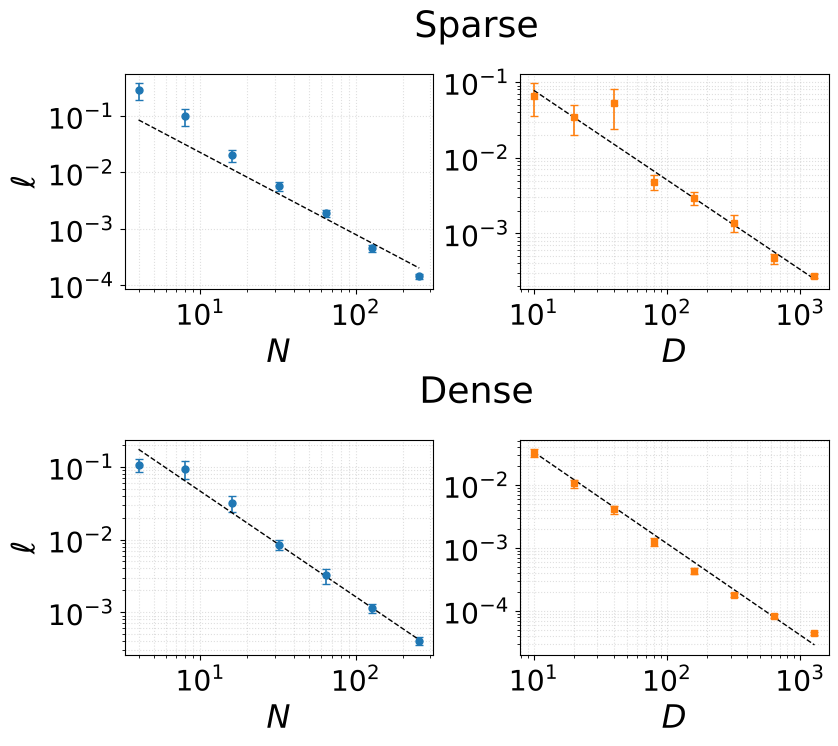

In [ ]:
def plot_scaling_fits_shared(results, tail_fit=4, save_path=None):
    """
    Four-panel figure (Sparse top, Dense bottom; N-sweep left, D-sweep right).
    Three of the four panels (Gaussian N, Gaussian D, Sparse N) share a single
    fitted exponent. Sparse D-sweep uses its own independent fit.
    Empirical points with error bars + black dashed lines.
    """
    res_g = results["gaussian_powerlaw"]
    res_s = results["sparse"]

    # Empirical points
    Ns_g = np.array(sorted(res_g["N"].keys()), dtype=float)
    Ng_means = np.array([res_g["N"][int(N)][0] for N in Ns_g])
    Ng_sems = np.array([res_g["N"][int(N)][1] for N in Ns_g])

    Ds_g = np.array(sorted(res_g["D"].keys()), dtype=float)
    Dg_means = np.array([res_g["D"][int(D)][0] for D in Ds_g])
    Dg_sems = np.array([res_g["D"][int(D)][1] for D in Ds_g])

    Ns_s = np.array(sorted(res_s["N"].keys()), dtype=float)
    Ns_means = np.array([res_s["N"][int(N)][0] for N in Ns_s])
    Ns_sems = np.array([res_s["N"][int(N)][1] for N in Ns_s])

    Ds_s = np.array(sorted(res_s["D"].keys()), dtype=float)
    Ds_means = np.array([res_s["D"][int(D)][0] for D in Ds_s])
    Ds_sems = np.array([res_s["D"][int(D)][1] for D in Ds_s])

    # Joint shared-slope fit on tails: 3 sweeps, one common slope, three intercepts
    Ns_g_tail = Ns_g[-tail_fit:]
    Ng_means_tail = Ng_means[-tail_fit:]
    Ds_g_tail = Ds_g[-tail_fit:]
    Dg_means_tail = Dg_means[-tail_fit:]
    Ns_s_tail = Ns_s[-tail_fit:]
    Ns_means_tail = Ns_means[-tail_fit:]

    n1 = len(Ns_g_tail); n2 = len(Ds_g_tail); n3 = len(Ns_s_tail)
    A = np.zeros((n1 + n2 + n3, 4))                     # [slope, c_gN, c_gD, c_sN]
    A[:n1, 0] = np.log(Ns_g_tail);    A[:n1, 1] = 1.0
    A[n1:n1+n2, 0] = np.log(Ds_g_tail); A[n1:n1+n2, 2] = 1.0
    A[n1+n2:, 0] = np.log(Ns_s_tail); A[n1+n2:, 3] = 1.0
    b = np.concatenate([np.log(Ng_means_tail),
                        np.log(Dg_means_tail),
                        np.log(Ns_means_tail)])

    coeffs, *_ = np.linalg.lstsq(A, b, rcond=None)
    slope_shared, ic_gN, ic_gD, ic_sN = coeffs
    a_shared = -float(slope_shared)

    # Independent fit for the Sparse D-sweep
    aD_s_indep, ic_sD = fit_powerlaw(Ds_s, Ds_means, tail=tail_fit)

    print(f"Joint shared exponent (Gaussian N, Gaussian D, Sparse N): α = {a_shared:.3f}")
    print(f"Independent fit for Sparse D-sweep:                       α = {aD_s_indep:.3f}")

    # Plot
    fig, axes = plt.subplots(2, 2, figsize=(8, 7), constrained_layout=False)
    fig.subplots_adjust(left=0.09, right=0.97, top=0.92, bottom=0.09,
                         wspace=0.28, hspace=0.7)

    # Sparse N-sweep (top-left): shared exponent
    ax = axes[0, 0]
    ax.errorbar(Ns_s, Ns_means, yerr=Ns_sems, fmt="o", capsize=3,
                color="C0", markersize=5, linewidth=1, elinewidth=1.2)
    ax.plot(Ns_s, np.exp(ic_sN) * Ns_s ** -a_shared,
            color="black", linestyle="--", linewidth=1.0)
    ax.set_xscale("log"); ax.set_yscale("log")
    ax.set_xlabel(r"$N$"); ax.set_ylabel(r"$\ell$")
    ax.grid(True, which="both", ls=":", alpha=0.4)

    # Sparse D-sweep (top-right): independent fit
    ax = axes[0, 1]
    ax.errorbar(Ds_s, Ds_means, yerr=Ds_sems, fmt="s", capsize=3,
                color="C1", markersize=5, linewidth=1, elinewidth=1.2)
    ax.plot(Ds_s, np.exp(ic_sD) * Ds_s ** -aD_s_indep,
            color="black", linestyle="--", linewidth=1.0)
    ax.set_xscale("log"); ax.set_yscale("log")
    ax.set_xlabel(r"$D$"); ax.set_ylabel(r"$\ell$")
    ax.grid(True, which="both", ls=":", alpha=0.4)

    # Dense N-sweep (bottom-left): shared exponent
    ax = axes[1, 0]
    ax.errorbar(Ns_g, Ng_means, yerr=Ng_sems, fmt="o", capsize=3,
                color="C0", markersize=5, linewidth=1, elinewidth=1.2)
    ax.plot(Ns_g, np.exp(ic_gN) * Ns_g ** -a_shared,
            color="black", linestyle="--", linewidth=1.0)
    ax.set_xscale("log"); ax.set_yscale("log")
    ax.set_xlabel(r"$N$"); ax.set_ylabel(r"$\ell$")
    ax.grid(True, which="both", ls=":", alpha=0.4)

    # Dense D-sweep (bottom-right): shared exponent
    ax = axes[1, 1]
    ax.errorbar(Ds_g, Dg_means, yerr=Dg_sems, fmt="s", capsize=3,
                color="C1", markersize=5, linewidth=1, elinewidth=1.2)
    ax.plot(Ds_g, np.exp(ic_gD) * Ds_g ** -a_shared,
            color="black", linestyle="--", linewidth=1.0)
    ax.set_xscale("log"); ax.set_yscale("log")
    ax.set_xlabel(r"$D$"); ax.set_ylabel(r"$\ell$")
    ax.grid(True, which="both", ls=":", alpha=0.4)

    # The right-hand panels share the loss axis with the left-hand ones
    axes[0, 1].set_ylabel(""); axes[1, 1].set_ylabel("")
    # One labelled tick per decade on every axis, as in the original
    for a in axes.flat:
        a.xaxis.set_major_locator(ticker.LogLocator(base=10, numticks=20))
        a.yaxis.set_major_locator(ticker.LogLocator(base=10, numticks=20))

    # Row labels
    row_labels = ["Sparse", "Dense"]
    for row, label in enumerate(row_labels):
        bbox_left = axes[row, 0].get_position()
        bbox_right = axes[row, 1].get_position()
        x_center = (bbox_left.x0 + bbox_right.x1) / 2
        y_top = bbox_left.y1 + 0.04
        fig.text(x_center, y_top, label, ha="center", va="bottom", fontsize=F4_ROW)

    if save_path:
        plt.savefig(save_path, bbox_inches="tight")
        print(f"Figure saved to: {save_path}")
    plt.show()
    return fig


fig4 = plot_scaling_fits_shared(results_relu_nesterov, tail_fit=4, save_path="../figures/Figure4.pdf")
fig4.savefig("../figures/Figure4.png", dpi=300, bbox_inches="tight")


## Experiment code (original, for reference; not re-run here)

The cells below are the original Colab notebook that produced the archived results: setup (mounts Google Drive), data samplers, the two-layer network with Nesterov training, the sweep driver, a spot check and the full run (one A100, about 30 minutes). They are not executed here.

In [ ]:
from google.colab import drive
drive.mount('/content/drive')

import os
DRIVE_DIR = '/content/drive/MyDrive/sparse_scaling_laws/'
os.makedirs(DRIVE_DIR, exist_ok=True)
print(f"Saving to: {DRIVE_DIR}")

import math
import time
import pickle
from datetime import datetime
import numpy as np
import torch
import torch.nn as nn
import matplotlib.pyplot as plt
from dataclasses import dataclass
from tqdm.auto import tqdm

device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
torch.set_default_dtype(torch.float32)
torch.backends.cuda.matmul.allow_tf32 = True
torch.backends.cudnn.allow_tf32 = True

# Match figure styling used in other paper figures
plt.rcParams.update({
    "font.size": 11,
    "axes.labelsize": 12,
    "axes.titlesize": 12,
    "legend.fontsize": 10,
    "xtick.labelsize": 10,
    "ytick.labelsize": 10,
    "axes.linewidth": 0.8,
})

print(f"Using device: {device}")
if torch.cuda.is_available():
    print(f"GPU: {torch.cuda.get_device_name(0)}")

@dataclass
class Config:
    alpha1: float = 1.0
    alpha2: float = 0.3
    M: int = 10_000
    n_test: int = 20_000
    n_seeds: int = 5

In [ ]:
def sample_sparse(n, cfg: Config):
    """Sparse Bernoulli x heavy-tailed amplitude."""
    j = torch.arange(1, cfg.M + 1, device=device, dtype=torch.float32)
    p = j.pow(-(cfg.alpha1 + 1.0))
    amp = j.pow(-(cfg.alpha2 + 1.0) / 2.0)
    mask = (torch.rand(n, cfg.M, device=device) < p)
    signs = torch.where(
        torch.rand(n, cfg.M, device=device) < 0.5,
        torch.tensor(-1.0, dtype=torch.float32, device=device),
        torch.tensor(1.0, dtype=torch.float32, device=device),
    )
    X = mask.float() * signs * amp
    return X

def sample_gaussian_powerlaw(n, cfg: Config):
    """Dense baseline, matched tail exponent."""
    alpha = cfg.alpha1 + cfg.alpha2 + 1.0
    j = torch.arange(1, cfg.M + 1, device=device, dtype=torch.float32)
    std = j.pow(-(alpha + 1.0) / 2.0)
    X = torch.randn(n, cfg.M, device=device, dtype=torch.float32) * std
    return X

def make_teacher(cfg: Config, generator=None):
    return torch.randn(cfg.M, device=device, dtype=torch.float32, generator=generator)

In [ ]:
class TwoLayerNet(nn.Module):
    def __init__(self, N, M, activation="relu"):
        super().__init__()
        u = torch.randn(N, M, dtype=torch.float32) / math.sqrt(N)
        self.u = nn.Parameter(u, requires_grad=False)
        self.theta = nn.Parameter(torch.zeros(N, dtype=torch.float32))
        self.activation = activation

    def forward(self, x):
        h = x @ self.u.T
        if self.activation == "relu":
            h = torch.relu(h)
        return h @ self.theta


def train_and_eval_relu_gd(N, D, cfg: Config, data_sampler, seed: int,
                            max_steps=500_000, verbose=False):
    """
    ReLU random features + Nesterov GD on the readout.
    First layer u is fixed (random projection), ReLU applied, readout trained.
    Float64 on GPU. Returns (test_mse, train_mse, steps_used).
    """
    g = torch.Generator(device=device).manual_seed(seed)
    w = make_teacher(cfg, generator=g)

    X_train = data_sampler(D, cfg)
    y_train = X_train @ w
    X_test = data_sampler(cfg.n_test, cfg)
    y_test = X_test @ w

    model = TwoLayerNet(N, cfg.M, "relu").to(device)

    with torch.no_grad():
        # Precompute ReLU features in float64.
        Phi_train = torch.relu(X_train @ model.u.T).double()       # (D, N)
        Phi_test  = torch.relu(X_test  @ model.u.T).double()       # (n_test, N)
        y64_train = y_train.double()
        y64_test  = y_test.double()
        D_train = Phi_train.shape[0]

        # lambda_max via power iteration
        v = torch.randn(Phi_train.shape[1], dtype=torch.float64, device=device)
        v /= v.norm()
        for _ in range(50):
            v = Phi_train.T @ (Phi_train @ v) / D_train
            nrm = v.norm()
            if nrm < 1e-30:
                break
            v /= nrm
        lam_max = (v @ (Phi_train.T @ (Phi_train @ v) / D_train)).item()
        lam_max = max(lam_max, 1e-30)
        eta = 1.0 / lam_max

        # Nesterov + adaptive restart
        theta = torch.zeros(Phi_train.shape[1], dtype=torch.float64, device=device)
        y_prev = theta.clone()

        init_resid = Phi_train @ theta - y64_train
        init_grad_norm = ((Phi_train.T @ init_resid) / D_train).norm().item()
        init_grad_norm = max(init_grad_norm, 1e-30)

        steps_used = max_steps
        k_since_restart = 0
        for k in range(max_steps):
            resid = Phi_train @ theta - y64_train
            grad = (Phi_train.T @ resid) / D_train
            y_new = theta - eta * grad
            mom = (k_since_restart - 1.0) / (k_since_restart + 2.0) if k_since_restart >= 1 else 0.0
            theta_new = y_new + mom * (y_new - y_prev)

            # Adaptive restart: reset momentum if moving uphill
            if k_since_restart >= 1 and (grad @ (theta_new - theta)).item() > 0:
                k_since_restart = 0
                y_prev = theta.clone()
                theta = theta - eta * grad
                continue

            theta = theta_new
            y_prev = y_new
            k_since_restart += 1

            if k % 500 == 499:
                gnorm = grad.norm().item()
                if not np.isfinite(gnorm):
                    steps_used = k + 1
                    break
                if gnorm < 1e-9 * init_grad_norm:
                    steps_used = k + 1
                    break

        final_train_loss = 0.5 * ((Phi_train @ theta - y64_train) ** 2).mean().item()
        rel_grad = ((Phi_train.T @ (Phi_train @ theta - y64_train)) / D_train).norm().item() / init_grad_norm

        test_pred = Phi_test @ theta
        test_mse = ((test_pred - y64_test) ** 2).mean().item()

    if verbose:
        print(f"  N={N} D={D} eta={eta:.1e} steps={steps_used} "
              f"train={final_train_loss:.2e} rel_grad={rel_grad:.1e} test={test_mse:.2e}")
    return test_mse, final_train_loss, steps_used

In [ ]:
def fit_powerlaw(xs, ys, tail=None):
    xs, ys = np.asarray(xs, dtype=float), np.asarray(ys, dtype=float)
    if tail is not None:
        xs, ys = xs[-tail:], ys[-tail:]
    lx, ly = np.log(xs), np.log(ys)
    A = np.vstack([lx, np.ones_like(lx)]).T
    coeffs, *_ = np.linalg.lstsq(A, ly, rcond=None)
    return -float(coeffs[0]), float(coeffs[1])


def sweep_N_relu(N_list, D_fixed, cfg, data_sampler, desc=""):
    out, diagnostics = {}, {}
    pbar = tqdm(N_list, desc=f"{desc} [ReLU] N-sweep", leave=True)
    for N in pbar:
        losses, train_losses, steps_list = [], [], []
        for s in range(cfg.n_seeds):
            tmse, tr, st = train_and_eval_relu_gd(N, D_fixed, cfg, data_sampler, seed=s)
            losses.append(tmse); train_losses.append(tr); steps_list.append(st)
            pbar.set_postfix(N=N, seed=f"{s+1}/{cfg.n_seeds}",
                             test=f"{np.mean(losses):.2e}",
                             steps=f"{int(np.mean(steps_list))}")
        out[N] = (float(np.mean(losses)),
                   float(np.std(losses) / np.sqrt(len(losses))))
        diagnostics[N] = dict(train_loss=float(np.mean(train_losses)),
                              steps=float(np.mean(steps_list)))
    return out, diagnostics


def sweep_D_relu(D_list, N_fixed, cfg, data_sampler, desc=""):
    out, diagnostics = {}, {}
    pbar = tqdm(D_list, desc=f"{desc} [ReLU] D-sweep", leave=True)
    for D in pbar:
        losses, train_losses, steps_list = [], [], []
        for s in range(cfg.n_seeds):
            tmse, tr, st = train_and_eval_relu_gd(N_fixed, D, cfg, data_sampler, seed=s)
            losses.append(tmse); train_losses.append(tr); steps_list.append(st)
            pbar.set_postfix(D=D, seed=f"{s+1}/{cfg.n_seeds}",
                             test=f"{np.mean(losses):.2e}",
                             steps=f"{int(np.mean(steps_list))}")
        out[D] = (float(np.mean(losses)),
                   float(np.std(losses) / np.sqrt(len(losses))))
        diagnostics[D] = dict(train_loss=float(np.mean(train_losses)),
                              steps=float(np.mean(steps_list)))
    return out, diagnostics


def plot_scaling_fits(results, tail_fit=4, save_path=None):
    """
    Four-panel figure (Sparse top, Dense bottom; N-sweep left, D-sweep right).
    Empirical points with error bars + black dashed asymptotic-fit line
    extended across the whole panel. Row labels above each row.
    """
    fig, axes = plt.subplots(2, 2, figsize=(8, 7), constrained_layout=False)
    fig.subplots_adjust(left=0.09, right=0.97, top=0.92, bottom=0.09,
                         wspace=0.28, hspace=0.55)

    dataset_names = ["sparse", "gaussian_powerlaw"]
    row_labels = ["Sparse", "Dense"]

    for row, ds_name in enumerate(dataset_names):
        res = results[ds_name]

        # N-sweep
        ax = axes[row, 0]
        Ns = np.array(sorted(res["N"].keys()), dtype=float)
        means = np.array([res["N"][int(N)][0] for N in Ns])
        sems = np.array([res["N"][int(N)][1] for N in Ns])
        ax.errorbar(Ns, means, yerr=sems, fmt="o", capsize=3,
                    color="C0", markersize=5, linewidth=1, elinewidth=1.2)
        aN_fit, intercept_N = fit_powerlaw(Ns, means, tail=tail_fit)
        ax.plot(Ns, np.exp(intercept_N) * Ns ** -aN_fit,
                color="black", linestyle="--", linewidth=1.0)
        ax.set_xscale("log"); ax.set_yscale("log")
        ax.set_xlabel(r"$N$"); ax.set_ylabel(r"$\ell$")
        ax.grid(True, which="both", ls=":", alpha=0.4)

        # D-sweep
        ax = axes[row, 1]
        Ds = np.array(sorted(res["D"].keys()), dtype=float)
        means = np.array([res["D"][int(D)][0] for D in Ds])
        sems = np.array([res["D"][int(D)][1] for D in Ds])
        ax.errorbar(Ds, means, yerr=sems, fmt="s", capsize=3,
                    color="C1", markersize=5, linewidth=1, elinewidth=1.2)
        aD_fit, intercept_D = fit_powerlaw(Ds, means, tail=tail_fit)
        ax.plot(Ds, np.exp(intercept_D) * Ds ** -aD_fit,
                color="black", linestyle="--", linewidth=1.0)
        ax.set_xscale("log"); ax.set_yscale("log")
        ax.set_xlabel(r"$D$"); ax.set_ylabel(r"$\ell$")
        ax.grid(True, which="both", ls=":", alpha=0.4)

    # Row labels above each row
    for row, label in enumerate(row_labels):
        bbox_left = axes[row, 0].get_position()
        bbox_right = axes[row, 1].get_position()
        x_center = (bbox_left.x0 + bbox_right.x1) / 2
        y_top = bbox_left.y1 + 0.04
        fig.text(x_center, y_top, label, ha="center", va="bottom", fontsize=14)

    if save_path:
        plt.savefig(save_path, bbox_inches="tight")
        print(f"Figure saved to: {save_path}")
    plt.show()
    return fig

In [ ]:
def run_experiment_relu(cfg: Config, save_prefix=""):
    results = {}
    N_list = [4, 8, 16, 32, 64, 128, 256]
    D_for_N_sweep = 50_000
    D_list = [10, 20, 40, 80, 160, 320, 640, 1280]
    N_for_D_sweep = 8000

    datasets = [("sparse", sample_sparse),
                ("gaussian_powerlaw", sample_gaussian_powerlaw)]

    t0 = time.time()
    for name, sampler in tqdm(datasets, desc="datasets [ReLU]", position=0):
        N_results, N_diag = sweep_N_relu(N_list, D_for_N_sweep, cfg, sampler, desc=name)
        D_results, D_diag = sweep_D_relu(D_list, N_for_D_sweep, cfg, sampler, desc=name)

        alpha_N, _ = fit_powerlaw(list(N_results.keys()),
                                  [v[0] for v in N_results.values()], tail=4)
        alpha_D, _ = fit_powerlaw(list(D_results.keys()),
                                  [v[0] for v in D_results.values()], tail=4)

        tqdm.write(f"\n[ReLU][{name}] alpha_N = {alpha_N:.3f}, alpha_D = {alpha_D:.3f}")
        results[name] = dict(N=N_results, D=D_results,
                             alpha_N=alpha_N, alpha_D=alpha_D,
                             N_diag=N_diag, D_diag=D_diag)

        # Per-dataset Drive checkpoint
        ts = datetime.now().strftime("%Y%m%d_%H%M%S")
        path = os.path.join(DRIVE_DIR,
                              f"checkpoint_{save_prefix}relu_nesterov_{name}_{ts}.pkl")
        with open(path, "wb") as f:
            pickle.dump({"results": results, "config": cfg}, f)
        print(f"  Checkpoint saved: {path}", flush=True)

    a1, a2 = cfg.alpha1, cfg.alpha2
    tqdm.write("\n=== Linear theory (for reference; ReLU may differ) ===")
    tqdm.write(f"Sparse:   alpha_N = {a1+a2+1:.3f}, alpha_D = {(a1+a2+1)/(a1+1):.3f}")
    tqdm.write(f"Gaussian: alpha_N = alpha_D = {a1+a2+1:.3f}")
    tqdm.write(f"\ntotal time: {time.time()-t0:.1f}s")
    return results

In [ ]:
print("=" * 60)
print("Spot check: ReLU+Nesterov, sparse, N=8000, D=1280, seed=0")
print("=" * 60)
t0 = time.time()
test_mse, train_mse, steps = train_and_eval_relu_gd(
    N=8000, D=1280, cfg=Config(),
    data_sampler=sample_sparse, seed=0, verbose=True,
)
print(f"  elapsed: {time.time()-t0:.1f}s")

In [ ]:
results_relu_nesterov = run_experiment_relu(Config())